Today's topics:

* selecting rows with masks
* fitting a plane with `minimize`
* scoring a fit with RMSE and $R^2$
* contour plots
* checking residuals

# How water changes the strength of concrete

Today we will model a whole dataset, from selecting rows to making a prediction.

Concrete is cement, water, sand, and gravel mixed and left to harden.

The cement reacts with the water (**hydration**).
The reaction products bind the sand and gravel together.

The products fill part of the space the water occupied.
At a higher water/cement ratio, more of that space can remain as pores.
A porous paste is generally weaker.


<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/2/29/Concrete_Compression_Testing.jpg/960px-Concrete_Compression_Testing.jpg" alt="A gray concrete cylinder standing between the steel platens of a testing machine, with two strain gauges clipped to its sides" width=300/>

*Photo by Xb-70, public domain, [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Concrete_Compression_Testing.jpg).*

Above: a concrete cylinder in a [compression test](https://en.wikipedia.org/wiki/Compressive_strength).

The press loads the cylinder until it crushes.
The **compressive strength** is the stress at failure.

A common reference age for the test is 28 days.

Engineers describe the water in a mix with the **water/cement ratio**, the mass of water divided by the mass of cement.

For otherwise comparable mixes, [Abrams](https://commons.wikimedia.org/wiki/File:Design_of_concrete_mixtures_(IA_designofconcrete00abrarich).pdf) reported in 1918 that compressive strength decreases as this ratio rises.

Today we'll model the amounts of cement and water directly.

The data are from I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," *Cement and Concrete Research* 28 (1998) 1797-1808, shared on the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength) under CC BY 4.0.

Each row is one mix.

Suppose a truck delivers a batch with 20 kg/m$^3$ more water than the recipe calls for.
What strength does a model of these mixes predict for that batch?
How far can we trust the prediction?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

In [2]:
#@title Load the concrete data and give the columns short names (click ▶ to run) { display-mode: "form" }
data = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/concrete.csv')
data.columns = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer',
                'coarse_agg', 'fine_agg', 'age', 'strength']

# Reading and selecting rows of a DataFrame

## Read and inspect

In [3]:
display(data)

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.284354
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.178794
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.696601
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.768036


One row is one mix.
The ingredient columns are in kg/m$^3$.
`age` is in days and `strength` is in MPa.

## Select one population

Slag and fly ash replace part of the cement.
We keep the plain-cement mixes with neither one.

Strength also changes as the concrete keeps hardening.
We keep one age, 28 days.

Each condition is a mask.
`&` keeps the rows where both masks are `True`.

In [4]:
is_plain = (data['slag'] == 0) & (data['fly_ash'] == 0)  # & joins the masks
is_28 = data['age'] == 28

mixes = data.loc[is_plain & is_28]  # rows where both are True
print(np.sum(is_plain), np.sum(is_28), len(mixes))  # plain, 28 days, both

232 425 80


Our population is the 80 rows in `mixes`.

Let's pull out cement, water, and strength and print the minimum and maximum of each.

In [5]:
cement = mixes['cement']
water = mixes['water']
strength = mixes['strength']

print(np.min(cement), np.max(cement))
print(np.min(water), np.max(water))
print(np.min(strength), np.max(strength))

200.0 540.0
140.0 228.0
12.24509376 79.98611076


# Plotting strength against the mix

## Water/cement ratio

The ratio is one elementwise division of two columns.

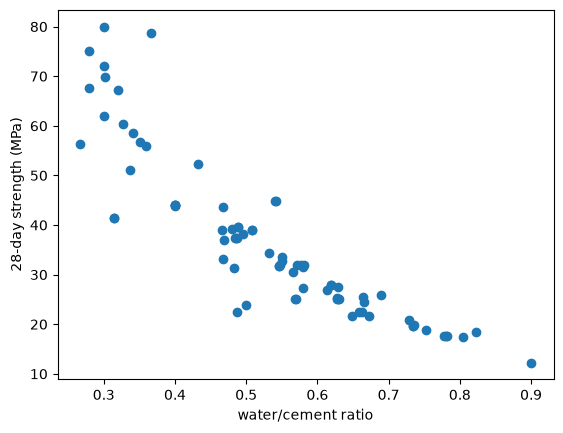

In [6]:
wc = water / cement  # elementwise division

fig, ax = plt.subplots()
ax.scatter(wc, strength)
ax.set_xlabel('water/cement ratio')
ax.set_ylabel('28-day strength (MPa)')
plt.show()

The mixes with more water per unit of cement are weaker, the same trend Abrams reported.

We'll leave the ratio out of our model.
We'll use the cement and water amounts as two separate inputs.

## Color for a third variable

Cement and water give the two axes.
The color shows the strength.

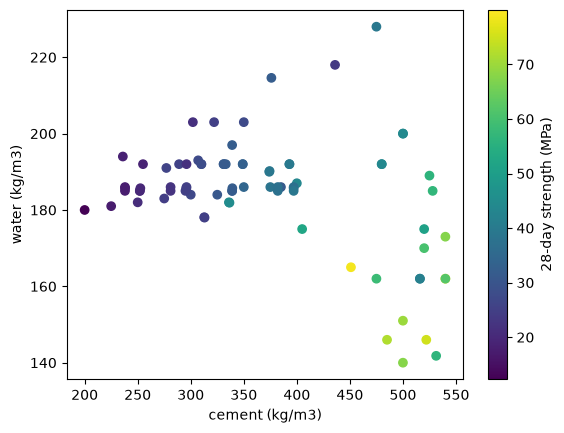

In [7]:
fig, ax = plt.subplots()
im = ax.scatter(cement, water, c=strength, cmap='viridis')  # c: one number per mix
cb = fig.colorbar(im, ax=ax)
cb.set_label('28-day strength (MPa)')
ax.set_xlabel('cement (kg/m3)')
ax.set_ylabel('water (kg/m3)')
plt.show()

The yellow marks, the strong mixes, sit toward the lower right: more cement and less water.
A plane in these two inputs is the simplest model for that trend.

### [Check your understanding]

Some mixes replace part of the cement with slag.
Let's see whether they follow the same trend.

1. Select the 28-day mixes that contain some slag. How many are there?
2. Plot water against cement for these mixes. Color each mix by its strength and make the plot readable on its own.
3. Where do the yellow markers, the strongest slag mixes, sit? Is it the same corner as the plain-cement mixes?

# Scoring a fit

We'll score every model with the same two helpers: `rmse` and `r_squared`.

In [8]:
def rmse(y, y_fit):
    """Root-mean-square error, in the units of y."""
    return np.sqrt(np.mean((y - y_fit)**2))

def r_squared(y, y_fit):
    """R2 of a fit: 1 minus the squared misfit over the squared spread of y."""
    return 1 - np.sum((y - y_fit)**2) / np.sum((y - np.mean(y))**2)

A model that always guesses the mean strength sets the baseline.

In [9]:
print('RMSE:', rmse(strength, np.mean(strength)).round(2))

RMSE: 15.85


The water/cement ratio gives a second baseline, a line fitted with `stats.linregress`.

In [10]:
fit_wc = stats.linregress(wc, strength)
strength_wc = fit_wc.slope * wc + fit_wc.intercept
print('RMSE:', rmse(strength, strength_wc).round(2))
print('R2:', r_squared(strength, strength_wc).round(3))

RMSE: 7.29
R2: 0.788


# Fitting a plane with `minimize`

A plane in two inputs has three parameters:

$$\text{strength} = a + b\,(\text{cement}) + c\,(\text{water})$$

This is the plane from last lecture with cement and water as the two inputs.

We write it as a model function with the inputs first and the parameters after them.

In [11]:
def plane(cement, water, a, b, c):
    """Strength in MPa from cement and water, both in kg/m3."""
    return a + b * cement + c * water

Let's write the objective as the mean squared residual of the plane.

In [12]:
def mse_plane(params):
    a, b, c = params  # one value per parameter
    residuals = strength - plane(cement, water, a, b, c)  # data minus plane
    return np.mean(residuals**2)

`x0` has one starting value for each of the three parameters, in the order of the unpack line.
We start all three at zero.

In [13]:
res = optimize.minimize(mse_plane, [0, 0, 0])
a_fit, b_fit, c_fit = res.x
print(res.success)
print(res.x.round(3))  # a, b, c

True
[51.807  0.124 -0.333]


At fixed water in this fitted plane, more cement goes with higher strength.
At fixed cement, more water goes with lower strength.

Each coefficient is the change in fitted strength in MPa for one more kg/m$^3$ of that ingredient.
The other ingredient is held fixed.

The intercept `a` is the strength at zero cement and zero water, far outside our mixes.

## Scoring the plane with RMSE and $R^2$

We call `plane` with our fitted parameters and score the result with the same helpers.

In [14]:
strength_fit = plane(cement, water, a_fit, b_fit, c_fit)

print('RMSE:', rmse(strength, strength_fit).round(2))
print('R2:', r_squared(strength, strength_fit).round(3))

RMSE: 6.47
R2: 0.833


The plane's typical miss is smaller than the miss of the mean-only guess.
It is also smaller than the miss of the water/cement line.

Here's the fitted plane in 3D. Drag to rotate it.

In [15]:
#@title Preview: the concrete plane in 3D (click > to run) { display-mode: "form" }
import plotly.graph_objects as go

C, W = np.meshgrid(np.linspace(200, 540, 21), np.linspace(140, 230, 21))
S = plane(C, W, a_fit, b_fit, c_fit)

# vertical line from each mix to the plane, with None between lines
line_x, line_y, line_z = [], [], []
for ci, wi, si, sf in zip(cement, water, strength, strength_fit):
    line_x += [ci, ci, None]
    line_y += [wi, wi, None]
    line_z += [si, sf, None]

fig = go.Figure()
fig.add_trace(go.Surface(x=C, y=W, z=S, colorscale='viridis', opacity=0.8,
                         showscale=False, name='fitted plane'))
fig.add_trace(go.Scatter3d(x=cement, y=water, z=strength, mode='markers',
                           name='mixes', marker=dict(size=4, color='black')))
fig.add_trace(go.Scatter3d(x=line_x, y=line_y, z=line_z, mode='lines',
                           name='residuals', line=dict(color='grey', width=4)))
fig.update_layout(scene=dict(xaxis_title='cement (kg/m3)',
                             yaxis_title='water (kg/m3)',
                             zaxis_title='28-day strength (MPa)',
                             aspectmode='manual',
                             aspectratio=dict(x=1.4, y=1.4, z=1),
                             camera=dict(eye=dict(x=1.0, y=-2.5, z=1.0))),
                  width=700, height=500, margin=dict(l=0, r=0, t=0, b=0))
fig

# Reading a contour plot

The plane gives a fitted strength at every point in the (cement, water) plane.

A **contour plot** draws that surface in two dimensions.
Each colored band covers points with about the same fitted strength.

We fill the bands with the `viridis` colormap and put the 80 mixes on top.

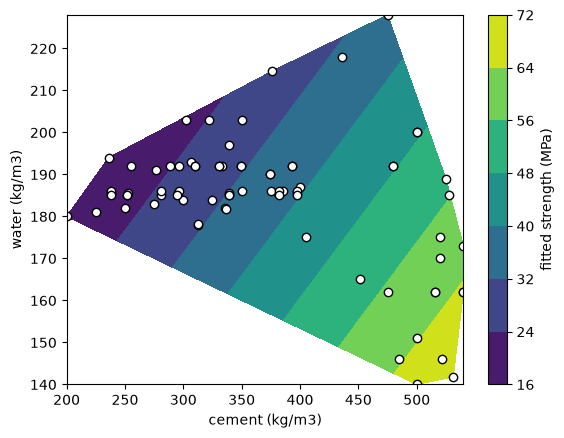

In [16]:
fig, ax = plt.subplots()
cs = ax.tricontourf(cement, water, strength_fit, cmap='viridis')
ax.scatter(cement, water, color='white', edgecolor='k')  # the 80 mixes
cb = fig.colorbar(cs, ax=ax)
cb.set_label('fitted strength (MPa)')
ax.set_xlabel('cement (kg/m3)')
ax.set_ylabel('water (kg/m3)')
plt.show()

The bands are straight and parallel because the form is a plane.

Moving right, toward more cement, crosses into bands closer to yellow.
Moving up, toward more water, crosses into bands closer to purple.

Moving along one band leaves the fitted strength unchanged.
Along a band, more cement offsets more water.

The ratio of the two coefficients gives the trade:

In [17]:
water_offset = 100 * b_fit / -c_fit
print(water_offset)  # kg/m3 of water that offsets 100 kg/m3 of cement

37.28384123445199


The filled map covers the region spanned by the mixes and stops outside it.

The lower left and the upper right corners hold no mixes.
No data support the plane there.

To predict from the plane, we call `plane` at a mix inside the cloud of white markers.
A mix with 400 kg/m$^3$ of cement and 185 kg/m$^3$ of water sits in the 32 to 40 MPa band.

In [18]:
strength_400_185 = plane(400, 185, a_fit, b_fit, c_fit)
print(strength_400_185)

39.85847462229445


### [Check your understanding]

Let's use the plane for the truck.

The recipe calls for 180 kg/m$^3$ of water with 350 kg/m$^3$ of cement.
The truck arrives with 200 kg/m$^3$ of water.

1. Predict the strength of the recipe mix and of the truck mix with the fitted plane. Find the difference.
2. Is that difference large compared with the plane's typical miss?
3. Copy the contour plot cell from above. Mark both mixes in a color that stands out. Do they sit inside the cloud of measured mixes?
4. A mix with 300 kg/m$^3$ of cement and 160 kg/m$^3$ of water is inside both ranges. Would you trust the plane's prediction there? Why or why not?

# Residuals against the fitted strength

An RMSE is one number for all 80 mixes.
We plot each residual against the fitted strength to see where the misses are.

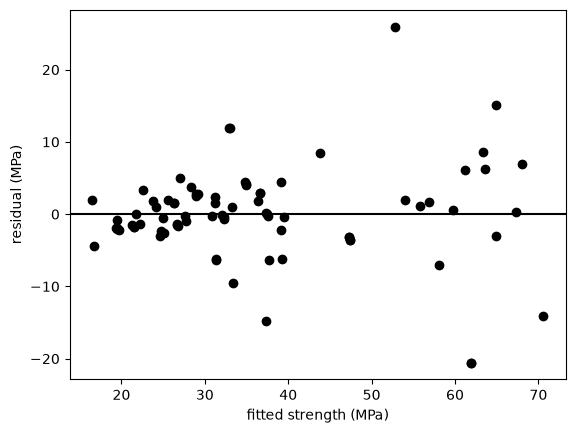

In [19]:
residuals = strength - strength_fit

fig, ax = plt.subplots()
ax.scatter(strength_fit, residuals, color='k')
ax.axhline(0, color='k')  # zero residual
ax.set_xlabel('fitted strength (MPa)')
ax.set_ylabel('residual (MPa)')
plt.show()

The residuals stay close to zero on the left and spread out on the right.
Let's compare the two halves with a mask on the fitted strength.

In [20]:
is_weak = strength_fit < 40
is_strong = strength_fit >= 40

std_weak = np.std(residuals.loc[is_weak])
std_strong = np.std(residuals.loc[is_strong])

print(np.sum(is_weak), std_weak.round(2))  # mixes fitted below 40 MPa, their spread
print(np.sum(is_strong), std_strong.round(2))  # mixes fitted 40 MPa and up, their spread

59 4.16
21 10.53


The misses are not spread equally across the fitted range.

The high fitted-strength group has larger errors under the plane.
The cause is open.

Other ingredients, nonlinear behavior, and measurement variation are all possibilities.

For a strong mix, the overall RMSE understates the spread we see on the right of the plot.

# Summary

* `&` joins masks to select the rows that meet several conditions.
* RMSE and $R^2$ compare a fit with simpler baselines on the same data.
* Along one band of a fitted contour, the two inputs trade off at a fixed prediction.
* A point can sit inside both input ranges and still lie outside the cloud of data.
* A residual plot against the fitted values shows where the misses are. A mask on the fitted values compares their spread.

# Midterm 2 review

Let's use the rest of class on the practice problems for Lectures 23-27 in the [Midterm 2 review notebook](https://colab.research.google.com/github/wfreinhart/matse219/blob/main/notebooks/Midterm2Review.ipynb).

## Further reading

* VanderPlas, *Python Data Science Handbook*, [Data Indexing and Selection](https://jakevdp.github.io/PythonDataScienceHandbook/03.02-data-indexing-and-selection.html), for masks and `.loc`
* VanderPlas, *Python Data Science Handbook*, [Density and Contour Plots](https://jakevdp.github.io/PythonDataScienceHandbook/04.04-density-and-contour-plots.html), for contours of a function on a regular grid
* Kong, Siauw, and Bayen, *Python Programming and Numerical Methods*, [Chapter 16, "Least Squares Regression"](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter16.00-Least-Squares-Regression.html)
* [`scipy.optimize.minimize` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)
* [`Axes.tricontourf` documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.tricontourf.html)